# Noise Cascades

When a signal is cascaded through a series of amplifiers with respective (linear) gains and noise temperatures $G_i$ and $T_i$, the total noise contribution is described by an effective (input-referred) noise temperature $T_{\rm e}$ given by the [Friis formula](https://en.wikipedia.org/wiki/Friis_formulas_for_noise):

$$
T_{\rm e}
=
T_1
+
\frac{T_2}{G_1}
+
\frac{T_3}{G_1 G_2}
+
\frac{T_4}{G_1 G_2 G_3}
+\cdots
$$

so for a series of low noise amplifiers, typically the noise from the first amplifier dominates. The total output noise temperature is the sum of the source noise temperature (physical temperature of a matched termination) and the effective noise temperature of the receiver chain.

Generally, the gain and noise temperature/figure for LNAs are provided as functions of frequency on the LNA spec sheet. Where a noise figure $F$ is provided, it can be converted to a noise temperature using
$$
T_{\rm amp} = (F - 1)\,T_{\rm ref} = \left(10^{F_{\rm dB}/10} - 1\right) T_{\rm ref}
$$
where $T_{\rm ref}$ is the reference noise temperature, conventionally taken to be 290 K.

Well-matched passive components can be mnodelled as attenuators with (linear) loss $L$. The equivalent (input-referred) noise temperature is
$$
T_{\rm att} = (L - 1)\,T_{\mathrm{phys}}
$$
where $T_{\rm phys}$ is the physical temperature of the attenuator.

By converting the loss into a "gain" using $G_{\rm att} = 1/L$, the attenuator can be added as a stage in the Friis equation using $T_{\rm att}$.

For reference, the output-referred noise temperature for an attenuator with input-noise $T_{\rm in}$ is
$$
T_{\rm out} = \frac{T_{\rm in}}{L} + \left(1 - \frac{1}{L}\right) T_{\rm phys}
$$
i.e., the output noise temperature is the weighted average of the input noise temperature and the physical temperature of the attenuator.

# iMNS Expected Noise Level

For the inductive magnon noise spectroscopyexperiments, we are working with a system of the form

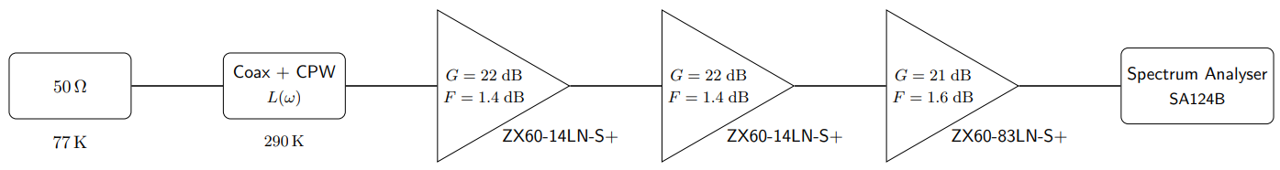

where the listed gains and noise figures for the amplifiers are representative values taken from the spec sheet data for 4 GHz. **To do: change representative values to tabulated/interpolated frequency-dependent values; it probably makes sense to split the attenuator into pre- and post-sample segments.**

Besides the LNAs, there is a lossy section consisting of the coaxial cable, coplanar waveguide and possibly the sample. 

The input-referred noise temperature at the spectrum analyser is thus
$$
T_{\rm sys} = T_{\rm source} + T_{\rm att} +
\frac{T_1}{G_{\rm att}}
+
\frac{T_2}{G_{\rm att} G_1}
+
\frac{T_3}{G_{\rm att} G_1 G_2}
$$
which we may convert to an output-referred noise temperature
$$
T_{\rm out} = G_{\mathrm{att}}G_1G_2G_3 \, T_{\rm sys}
$$
and hence to to an output noise power measured by the spectrum analyser
$$
P_{\rm out} = k_B B T_{\rm out}
$$
where $k_B$ is the Boltzmann constant and $B$ is the bandwidth over which the SA measures.

# Output Noise Power Estimation

The code below calculates the total expected noise at the spectrum analyser using the formulae above.

**For now I have set the temperature of the cables and coax to 290 K, while in reality there will be a temperature gradient from 77 K to room temperature over some length of the cable. Michael has a COMSOL model with which he can estimate the steady-state temperature gradient to obtain an effective temperature for the attenuator, otherwise the analysis below may be regarded as a worst case.**

In [2]:
# -----------------------------
# Module Import and Helper Functions
# -----------------------------

import numpy as np

def db_to_linear(x_db):
    return 10.0 ** (np.asarray(x_db, dtype=float) / 10.0)

def linear_to_db(x_lin):
    return 10.0 * np.log10(np.asarray(x_lin, dtype=float))


In [3]:
# -----------------------------
# Inputs
# -----------------------------
T_ref = 290.0 # K

# Physical temperature of 50 Ohm termination.
T_source = 77.0 # K (50 Ohm load in LN2)
# T_source = 9461 # K (Keysight 346C T_on)

# Loss and physical temperature of "coax + CPW" 
# section of the circuit. If you want to model 
# a temperature gradient you can add entries 
# to the array for each segment.
passive_losses_db = np.array([0.6, 1.5, 1.5, 0.5], dtype=float)
passive_temps_K = np.array([290.0, 290.0, 290.0, 290.0], dtype=float)

# Amplifier gains and noise figures in dB
amplifier_gains_db = np.array([22.0, 22.0, 21.0], dtype=float)
amplifier_nfs_db = np.array([1.4, 1.4, 1.6], dtype=float)

# SA settings
rbw_hz = 1e3

# -----------------------------
# Validation
# -----------------------------
if passive_losses_db.shape != passive_temps_K.shape:
    raise ValueError("passive_losses_db and passive_temps_K must have the same length.")

if amplifier_gains_db.shape != amplifier_nfs_db.shape:
    raise ValueError("amplifier_gains_db and amplifier_nfs_db must have the same length.")


# -----------------------------
# Stage conversion
# -----------------------------
passive_losses_lin = db_to_linear(passive_losses_db)
passive_gains_lin = 1.0 / passive_losses_lin
passive_noise_temps_K = (passive_losses_lin - 1.0) * passive_temps_K

amplifier_gains_lin = db_to_linear(amplifier_gains_db)
amplifier_noise_factors = db_to_linear(amplifier_nfs_db)
amplifier_noise_temps_K = (amplifier_noise_factors - 1.0) * T_ref


# -----------------------------
# Cascade
# -----------------------------
stage_gains_lin = np.concatenate([passive_gains_lin, amplifier_gains_lin])
stage_noise_temps_K = np.concatenate([passive_noise_temps_K, amplifier_noise_temps_K])
stage_types = np.array(
    ["passive"] * len(passive_gains_lin) + ["active"] * len(amplifier_gains_lin),
    dtype=object
)

Te_chain_K = 0.0
gain_before_stage = 1.0

for gain_i, Te_i in zip(stage_gains_lin, stage_noise_temps_K):
    Te_chain_K += Te_i / gain_before_stage
    gain_before_stage *= gain_i

T_system_K = T_source + Te_chain_K
G_total_lin = np.prod(stage_gains_lin)
G_total_db = linear_to_db(G_total_lin)

T_output_K = G_total_lin * T_system_K

k_B = 1.380649e-23
noise_density_W_per_Hz = k_B * T_system_K * G_total_lin
noise_density_dBm_per_Hz = 10.0 * np.log10(noise_density_W_per_Hz / 1e-3)
noise_power_in_rbw_dBm = noise_density_dBm_per_Hz + linear_to_db(rbw_hz)

# -----------------------------
# Contrast
# -----------------------------

T_reference_source_K = 290.0
T_output_reference_K = G_total_lin * T_reference_source_K

noise_density_reference_W_per_Hz = k_B * T_output_reference_K
noise_density_reference_dBm_per_Hz = 10.0 * np.log10(noise_density_reference_W_per_Hz / 1e-3)
noise_power_reference_in_rbw_dBm = noise_density_reference_dBm_per_Hz + linear_to_db(rbw_hz)

contrast_density_db = noise_density_dBm_per_Hz - noise_density_reference_dBm_per_Hz
contrast_power_db = noise_power_in_rbw_dBm - noise_power_reference_in_rbw_dBm

# -----------------------------
# Output
# -----------------------------
print("Stage summary:")
for i, (kind, gain_lin, gain_db, Te) in enumerate(
    zip(
        stage_types,
        stage_gains_lin,
        linear_to_db(stage_gains_lin),
        stage_noise_temps_K,
    ),
    start=1,
):
    print(
        f"  Stage {i:>2} | type={kind:<7} | "
        f"gain={gain_db:8.2f} dB ({gain_lin:5.1f} linear) | "
        f"Te={Te:4.0f} K"
    )

print("\nResults:")
print(f"  Source noise temperature           = {T_source:.0f} K")
print(f"  Receiver chain noise temperature   = {Te_chain_K:.0f} K")
print(f"  Total system noise temperature     = {T_system_K:.0f} K")
print(f"  Total gain                         = {G_total_db:.0f} dB")
print(f"  Noise spectral density at output   = {noise_density_dBm_per_Hz:.0f} dBm/Hz")
print(f"  Noise power in RBW ({rbw_hz:8.0f} Hz)   = {noise_power_in_rbw_dBm:.0f} dBm")

print("\nExpected iMNS contrast (assuming noise temp is 77 K just before the sample \nand is boosted to 290 K at resonance):")
print(f"  Noise density at output for 290 K ref     = {noise_density_reference_dBm_per_Hz:.0f} dBm/Hz")
print(f"  Noise power in RBW ({rbw_hz:.0f} Hz)           = {noise_power_reference_in_rbw_dBm:.0f} dBm")
print(f"  Contrast (actual - 290 K ref)             = {contrast_density_db:.0f} dB")

Stage summary:
  Stage  1 | type=passive | gain=   -0.60 dB (  0.9 linear) | Te=  43 K
  Stage  2 | type=passive | gain=   -1.50 dB (  0.7 linear) | Te= 120 K
  Stage  3 | type=passive | gain=   -1.50 dB (  0.7 linear) | Te= 120 K
  Stage  4 | type=passive | gain=   -0.50 dB (  0.9 linear) | Te=  35 K
  Stage  5 | type=active  | gain=   22.00 dB (158.5 linear) | Te= 110 K
  Stage  6 | type=active  | gain=   22.00 dB (158.5 linear) | Te= 110 K
  Stage  7 | type=active  | gain=   21.00 dB (125.9 linear) | Te= 129 K

Results:
  Source noise temperature           = 77 K
  Receiver chain noise temperature   = 741 K
  Total system noise temperature     = 818 K
  Total gain                         = 61 dB
  Noise spectral density at output   = -109 dBm/Hz
  Noise power in RBW (    1000 Hz)   = -79 dBm

Expected iMNS contrast (assuming noise temp is 77 K just before the sample 
and is boosted to 290 K at resonance):
  Noise density at output for 290 K ref     = -113 dBm/Hz
  Noise power in RBW

# Contrast

The contrast estimated above assumes the noise temperature stays fixed at 77 K until just before the sample, is boosted to 290 K at the resonant frequency and some intermediate temperature for non-resonant frequencies which depends on the (coax+CPW) loss and temperature.

Observed contrast between different source temperatures also depends on the output noise level and the noise floor of the spectrum analyser, particularly if the low-noise level is below the internal noise of the SA.

For reference, the noise floor of the [SA124B Spectrum Analyser](https://signalhound.com/sigdownloads/SA124B/SA124B-User-Manual.pdf) follows:
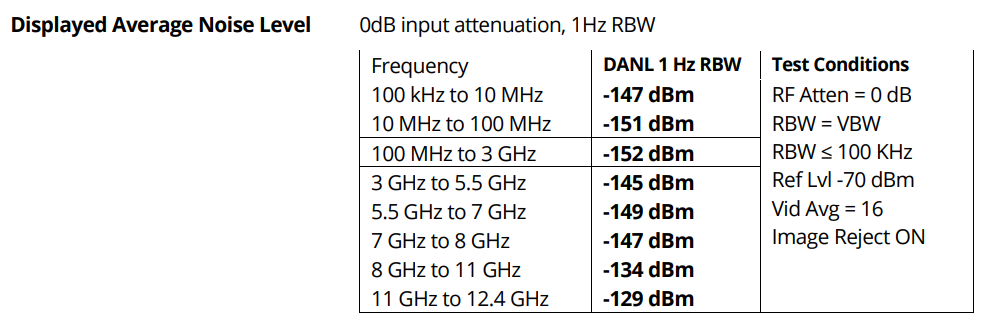